# DANet-S Final Test Evaluation

This notebook evaluates the selected Epoch 67 DANet-S checkpoint on the reserved NIH/NLM Malaria Cell Images test split. The test set contains 5,512 images and was not used for training or checkpoint selection. The notebook reports classification metrics, visual analysis, comparison with the base paper, limitations, and reproducibility artifacts.


## 1. Environment and shared artifacts

The setup verifies the available hardware and locates the data manifest, configuration, trained checkpoint, and model source.


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
TRAINING_DIR = PROJECT_DIR / "danet_training"
EVALUATION_DIR = PROJECT_DIR / "danet_evaluation"

MANIFEST_PATH = PROJECT_DIR / "split_manifest.csv"
DATA_CONFIG_PATH = PROJECT_DIR / "data_config.json"
CHECKPOINT_PATH = TRAINING_DIR / "danet_s_best_final.pth"
MODEL_SOURCE_PATH = TRAINING_DIR / "danet_model.py"

required_files = {
    "Split manifest": MANIFEST_PATH,
    "Data configuration": DATA_CONFIG_PATH,
    "Final checkpoint": CHECKPOINT_PATH,
    "Model source": MODEL_SOURCE_PATH,
}

EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

print("Evaluation directory:", EVALUATION_DIR)

for name, path in required_files.items():
    print(f"{name}: {path} | Found: {path.exists()}")

Evaluation directory: /content/drive/MyDrive/malaria_danet/danet_evaluation
Split manifest: /content/drive/MyDrive/malaria_danet/split_manifest.csv | Found: True
Data configuration: /content/drive/MyDrive/malaria_danet/data_config.json | Found: True
Final checkpoint: /content/drive/MyDrive/malaria_danet/danet_training/danet_s_best_final.pth | Found: True
Model source: /content/drive/MyDrive/malaria_danet/danet_training/danet_model.py | Found: True


In [4]:
import json

with open(DATA_CONFIG_PATH, "r", encoding="utf-8") as file:
    data_config = json.load(file)

print(json.dumps(data_config, indent=2))

{
  "dataset": "NIH/NLM Malaria Cell Images",
  "dataset_url": "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip",
  "base_paper": "DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "baseline_variant": "DANet-S with LogSoftMax",
  "total_images": 27558,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "split_seed": 42,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "split_counts": {
    "train": 19290,
    "validation": 2756,
    "test": 5512
  },
  "input_size": [
    224,
    224
  ],
  "pixel_scaling": "[0, 255] to [0, 1]",
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2
  },
  "batch_size": 64,
  "unreadable_images": 0,
  "exact_duplicate_groups": 0,
  "unique_official_patient_ids": 201,
  "pati

In [5]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())
print("\nSplit counts:")
print(manifest["split"].value_counts())
print("\nTest class counts:")
print(
    manifest.loc[manifest["split"] == "test", "class_name"]
    .value_counts()
    .sort_index()
)

Manifest shape: (27558, 9)
Columns: ['relative_path', 'filename', 'class_name', 'label', 'width', 'height', 'sha256', 'official_patient_id', 'split']

Split counts:
split
train         19290
test           5512
validation     2756
Name: count, dtype: int64

Test class counts:
class_name
Parasitized    2756
Uninfected     2756
Name: count, dtype: int64


## 2. Dataset reconstruction and validation

The public dataset is downloaded and matched against the saved split manifest. Every manifest path is verified before evaluation.


In [6]:
DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

DATA_ROOT = Path("/content/malaria_data")
ZIP_PATH = DATA_ROOT / "cell_images.zip"
IMAGE_DIR = DATA_ROOT / "cell_images"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset URL:", DATASET_URL)
print("Image directory:", IMAGE_DIR)
print("Dataset already available:", IMAGE_DIR.exists())

Dataset URL: https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip
Image directory: /content/malaria_data/cell_images
Dataset already available: False


In [7]:
print("Raw URL value:", repr(DATASET_URL))

assert DATASET_URL.startswith("https://")
assert DATASET_URL.endswith(".zip")
assert "[" not in DATASET_URL
assert "]" not in DATASET_URL
assert "(" not in DATASET_URL
assert ")" not in DATASET_URL

print("Dataset URL validation passed.")

Raw URL value: 'https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip'
Dataset URL validation passed.


In [8]:
from urllib.request import urlretrieve

if not ZIP_PATH.exists():
    urlretrieve(DATASET_URL, ZIP_PATH)
    print("Dataset archive downloaded.")
else:
    print("Dataset archive already exists.")

print("Archive path:", ZIP_PATH)
print("Archive size:", round(ZIP_PATH.stat().st_size / (1024**2), 1), "MB")

Dataset archive downloaded.
Archive path: /content/malaria_data/cell_images.zip
Archive size: 337.1 MB


In [9]:
import zipfile

if not IMAGE_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_ROOT)
    print("Dataset extraction complete.")
else:
    print("Dataset is already extracted.")

dataset_folders = sorted(
    path.name for path in IMAGE_DIR.iterdir() if path.is_dir()
)

print("Dataset folders:", dataset_folders)

Dataset extraction complete.
Dataset folders: ['Parasitized', 'Uninfected']


In [10]:
manifest_paths = manifest["relative_path"].map(IMAGE_DIR.__truediv__)
missing_paths = [path for path in manifest_paths if not path.exists()]

print("Manifest images:", len(manifest_paths))
print("Missing images:", len(missing_paths))

assert len(missing_paths) == 0, "Some manifest images are missing."

Manifest images: 27558
Missing images: 0


## 3. Reproducible test input pipeline

The test pipeline uses deterministic resizing and tensor conversion without training augmentation. The saved manifest defines the reserved test subset and class labels.


In [11]:
import random
import numpy as np

SEED = int(data_config["split_seed"])

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Reproducibility seed:", SEED)
print("Evaluation device:", DEVICE)

Reproducibility seed: 42
Evaluation device: cuda


In [12]:
from torchvision import transforms

INPUT_SIZE = tuple(data_config["input_size"])

evaluation_transform = transforms.Compose(
    [
        transforms.Resize(INPUT_SIZE),
        transforms.ToTensor(),
    ]
)

print(evaluation_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [13]:
from PIL import Image
from torch.utils.data import Dataset


class MalariaEvaluationDataset(Dataset):
    def __init__(self, dataframe, image_root, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        relative_path = row["relative_path"]

        return image, label, relative_path

In [14]:
test_manifest = (
    manifest.loc[manifest["split"] == "test"]
    .reset_index(drop=True)
    .copy()
)

test_dataset = MalariaEvaluationDataset(
    dataframe=test_manifest,
    image_root=IMAGE_DIR,
    transform=evaluation_transform,
)

print("Test samples:", len(test_dataset))
print("Expected test samples:", data_config["split_counts"]["test"])

assert len(test_dataset) == data_config["split_counts"]["test"]

Test samples: 5512
Expected test samples: 5512


In [15]:
sample_image, sample_label, sample_path = test_dataset[0]

print("Tensor shape:", sample_image.shape)
print("Tensor dtype:", sample_image.dtype)
print(
    "Pixel range:",
    float(sample_image.min()),
    "to",
    float(sample_image.max()),
)
print("Label:", sample_label)
print("Relative path:", sample_path)

Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
Pixel range: 0.0 to 0.886274516582489
Label: 0
Relative path: Uninfected/C100P61ThinF_IMG_20150918_144104_cell_131.png


In [16]:
from torch.utils.data import DataLoader

BATCH_SIZE = int(data_config["batch_size"])

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Data-loader workers:", test_loader.num_workers)

Test batches: 87
Batch size: 64
Data-loader workers: 0


In [17]:
batch_images, batch_labels, batch_paths = next(iter(test_loader))

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Image dtype:", batch_images.dtype)
print("Class counts:", torch.bincount(batch_labels, minlength=2))
print("Paths in batch:", len(batch_paths))

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Class counts: tensor([64,  0])
Paths in batch: 64


## 4. DANet-S model and selected checkpoint

The saved model source is loaded directly, the binary DANet-S architecture is reconstructed, and the Epoch 67 checkpoint is validated before inference.


In [18]:
import importlib.util

module_spec = importlib.util.spec_from_file_location(
    "danet_model",
    MODEL_SOURCE_PATH,
)
danet_model = importlib.util.module_from_spec(module_spec)
module_spec.loader.exec_module(danet_model)

print("Model source loaded from:", MODEL_SOURCE_PATH)
print("DANetS available:", hasattr(danet_model, "DANetS"))
print(
    "DilatedAttentionBlockS available:",
    hasattr(danet_model, "DilatedAttentionBlockS"),
)

Model source loaded from: /content/drive/MyDrive/malaria_danet/danet_training/danet_model.py
DANetS available: True
DilatedAttentionBlockS available: True


In [19]:
model = danet_model.DANetS(num_classes=2).to(DEVICE)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Device:", DEVICE)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

assert total_parameters == 2_310_842

Device: cuda
Total parameters: 2,310,842
Trainable parameters: 2,310,842


In [20]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

print("Checkpoint keys:", sorted(checkpoint.keys()))
print("Selected epoch:", checkpoint.get("epoch"))
print("Saved validation loss:", checkpoint.get("validation_loss"))
print("Saved validation accuracy:", checkpoint.get("validation_accuracy"))

Checkpoint keys: ['class_mapping', 'classifier_note', 'epoch', 'input_size', 'model_name', 'model_state_dict', 'num_classes', 'total_parameters', 'validation_accuracy', 'validation_loss']
Selected epoch: 67
Saved validation loss: 0.0959623521950815
Saved validation accuracy: 0.966255442670537


In [21]:
assert checkpoint["epoch"] == 67
assert checkpoint["num_classes"] == 2
assert tuple(checkpoint["input_size"]) == INPUT_SIZE
assert checkpoint["class_mapping"] == data_config["class_mapping"]

load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)
model.eval()

all_parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in model.parameters()
)

print("Missing state keys:", load_result.missing_keys)
print("Unexpected state keys:", load_result.unexpected_keys)
print("All parameters finite:", all_parameters_finite)
print("Model mode:", "evaluation" if not model.training else "training")

assert all_parameters_finite

Missing state keys: []
Unexpected state keys: []
All parameters finite: True
Model mode: evaluation


In [22]:
with torch.inference_mode():
    sample_outputs = model(batch_images[:2].to(DEVICE))
    sample_probabilities = sample_outputs.exp()

print("Output shape:", sample_outputs.shape)
print("All outputs finite:", torch.isfinite(sample_outputs).all().item())
print(
    "Probability sums:",
    sample_probabilities.sum(dim=1).cpu(),
)

assert sample_outputs.shape == (2, 2)
assert torch.isfinite(sample_outputs).all()
assert torch.allclose(
    sample_probabilities.sum(dim=1),
    torch.ones(2, device=DEVICE),
    atol=1e-5,
)

Output shape: torch.Size([2, 2])
All outputs finite: True
Probability sums: tensor([1.0000, 1.0000])


In [23]:
import torch.nn as nn

test_criterion = nn.NLLLoss(reduction="sum")

print("Test loss:", test_criterion)
print("Positive class:", data_config["class_mapping"]["Parasitized"])

Test loss: NLLLoss()
Positive class: 1


## 5. Final test evaluation

The selected checkpoint is evaluated once on the complete reserved test split. Per-image probabilities and predictions are retained for metric calculation and error analysis.


In [24]:
def evaluate_test_set(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    records = []

    with torch.inference_mode():
        for images, labels, relative_paths in data_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            log_probabilities = model(images)

            if not torch.isfinite(log_probabilities).all():
                raise RuntimeError("Non-finite model output detected.")

            total_loss += criterion(
                log_probabilities,
                labels,
            ).item()

            probabilities = log_probabilities.exp()
            predictions = probabilities.argmax(dim=1)
            confidences = probabilities.max(dim=1).values

            for index, relative_path in enumerate(relative_paths):
                records.append(
                    {
                        "relative_path": relative_path,
                        "true_label": int(labels[index].item()),
                        "predicted_label": int(predictions[index].item()),
                        "uninfected_probability": float(
                            probabilities[index, 0].item()
                        ),
                        "parasitized_probability": float(
                            probabilities[index, 1].item()
                        ),
                        "confidence": float(confidences[index].item()),
                    }
                )

    predictions_frame = pd.DataFrame(records)
    predictions_frame["correct"] = (
        predictions_frame["true_label"]
        == predictions_frame["predicted_label"]
    )

    average_loss = total_loss / len(data_loader.dataset)

    return average_loss, predictions_frame

In [25]:
import time

evaluation_start = time.perf_counter()

test_loss, test_predictions = evaluate_test_set(
    model=model,
    data_loader=test_loader,
    criterion=test_criterion,
    device=DEVICE,
)

evaluation_minutes = (
    time.perf_counter() - evaluation_start
) / 60

test_accuracy = test_predictions["correct"].mean()

print("Test samples evaluated:", len(test_predictions))
print("Test loss:", round(test_loss, 6))
print("Test accuracy:", round(test_accuracy, 6))
print(
    "Evaluation duration:",
    round(evaluation_minutes, 2),
    "minutes",
)
print(
    "All prediction values finite:",
    np.isfinite(
        test_predictions[
            [
                "uninfected_probability",
                "parasitized_probability",
                "confidence",
            ]
        ].to_numpy()
    ).all(),
)

Test samples evaluated: 5512
Test loss: 0.110878
Test accuracy: 0.963353
Evaluation duration: 0.37 minutes
All prediction values finite: True


In [26]:
label_to_class = {
    label: class_name
    for class_name, label in data_config["class_mapping"].items()
}

test_predictions["true_class"] = (
    test_predictions["true_label"].map(label_to_class)
)
test_predictions["predicted_class"] = (
    test_predictions["predicted_label"].map(label_to_class)
)

PREDICTIONS_PATH = EVALUATION_DIR / "test_predictions.csv"
test_predictions.to_csv(PREDICTIONS_PATH, index=False)

print("Predictions saved to:", PREDICTIONS_PATH)
print("Rows saved:", len(test_predictions))
print("Incorrect predictions:", (~test_predictions["correct"]).sum())

Predictions saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/test_predictions.csv
Rows saved: 5512
Incorrect predictions: 202


In [27]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

true_labels = test_predictions["true_label"].to_numpy()
predicted_labels = test_predictions["predicted_label"].to_numpy()
positive_probabilities = test_predictions[
    "parasitized_probability"
].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1],
).ravel()

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels)
recall = recall_score(true_labels, predicted_labels)
specificity = tn / (tn + fp)
f1 = f1_score(true_labels, predicted_labels)
roc_auc = roc_auc_score(
    true_labels,
    positive_probabilities,
)

print("Test loss:", f"{test_loss:.6f}")
print("Accuracy:", f"{accuracy:.6f}")
print("Precision:", f"{precision:.6f}")
print("Recall/Sensitivity:", f"{recall:.6f}")
print("Specificity:", f"{specificity:.6f}")
print("F1-score:", f"{f1:.6f}")
print("ROC-AUC:", f"{roc_auc:.6f}")
print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

Test loss: 0.110878
Accuracy: 0.963353
Precision: 0.968796
Recall/Sensitivity: 0.957547
Specificity: 0.969158
F1-score: 0.963139
ROC-AUC: 0.991887
TN: 2671 | FP: 85 | FN: 117 | TP: 2639


In [28]:
evaluation_metrics = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_samples": int(len(test_predictions)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall_sensitivity": float(recall),
    "specificity": float(specificity),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
    "evaluation_minutes": float(evaluation_minutes),
    "class_mapping": data_config["class_mapping"],
    "split_protocol": data_config["split_protocol"],
}

METRICS_PATH = EVALUATION_DIR / "test_metrics.json"

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(evaluation_metrics, file, indent=2)

print("Metrics saved to:", METRICS_PATH)
print(json.dumps(evaluation_metrics, indent=2))

Metrics saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/test_metrics.json
{
  "checkpoint_epoch": 67,
  "test_samples": 5512,
  "test_loss": 0.11087833183441792,
  "accuracy": 0.9633526850507983,
  "precision": 0.9687958883994127,
  "recall_sensitivity": 0.9575471698113207,
  "specificity": 0.9691582002902758,
  "f1_score": 0.9631386861313869,
  "roc_auc": 0.9918874059710862,
  "true_negatives": 2671,
  "false_positives": 85,
  "false_negatives": 117,
  "true_positives": 2639,
  "evaluation_minutes": 0.3683528753166684,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split"
}


## 6. Quantitative results and visualizations

The following cells report the confusion matrix, ROC curve, precision-recall curve, aggregate metrics, and class-wise results using one consistent visual theme.


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR = EVALUATION_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
)

COLORS = {
    "uninfected": "#4C78A8",
    "parasitized": "#E45756",
    "highlight": "#2CA25F",
    "curve": "#6F42C1",
}

plt.rcParams.update(
    {
        "figure.figsize": (8, 6),
        "figure.dpi": 120,
        "axes.titlesize": 15,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
    }
)

print("Figures directory:", FIGURES_DIR)

Figures directory: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures


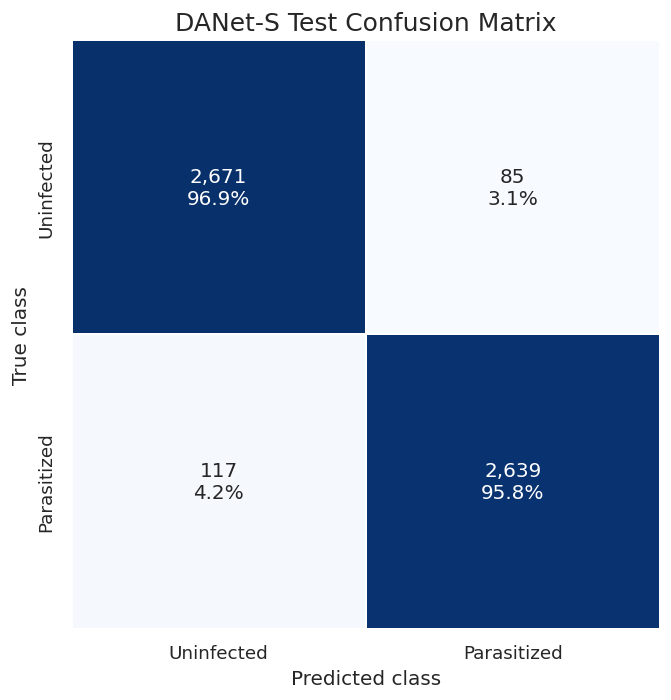

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/test_confusion_matrix.png


In [30]:
confusion = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1],
)

row_percentages = (
    confusion
    / confusion.sum(axis=1, keepdims=True)
    * 100
)

annotations = np.empty_like(confusion, dtype=object)

for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        annotations[row, column] = (
            f"{confusion[row, column]:,}\n"
            f"{row_percentages[row, column]:.1f}%"
        )

CONFUSION_MATRIX_PATH = (
    FIGURES_DIR / "test_confusion_matrix.png"
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion,
    annot=annotations,
    fmt="",
    cmap="Blues",
    cbar=False,
    square=True,
    linewidths=1,
    linecolor="white",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
)
plt.title("DANet-S Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", CONFUSION_MATRIX_PATH)

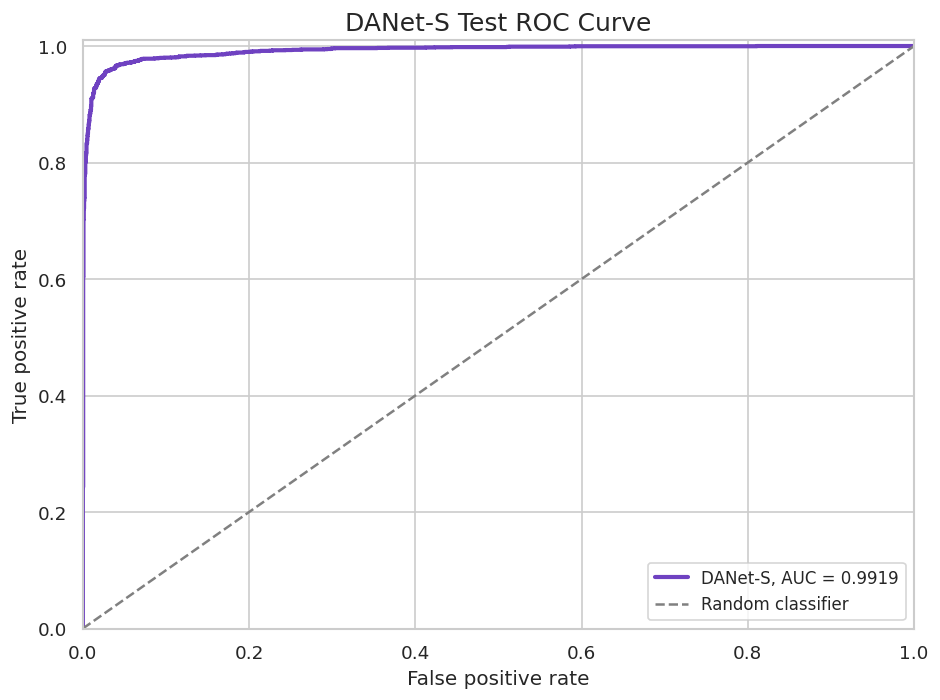

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/test_roc_curve.png


In [31]:
from sklearn.metrics import roc_curve

false_positive_rate, true_positive_rate, _ = roc_curve(
    true_labels,
    positive_probabilities,
)

ROC_CURVE_PATH = FIGURES_DIR / "test_roc_curve.png"

plt.figure(figsize=(8, 6))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    color=COLORS["curve"],
    linewidth=2.5,
    label=f"DANet-S, AUC = {roc_auc:.4f}",
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random classifier",
)
plt.xlim(0, 1)
plt.ylim(0, 1.01)
plt.title("DANet-S Test ROC Curve")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    ROC_CURVE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", ROC_CURVE_PATH)

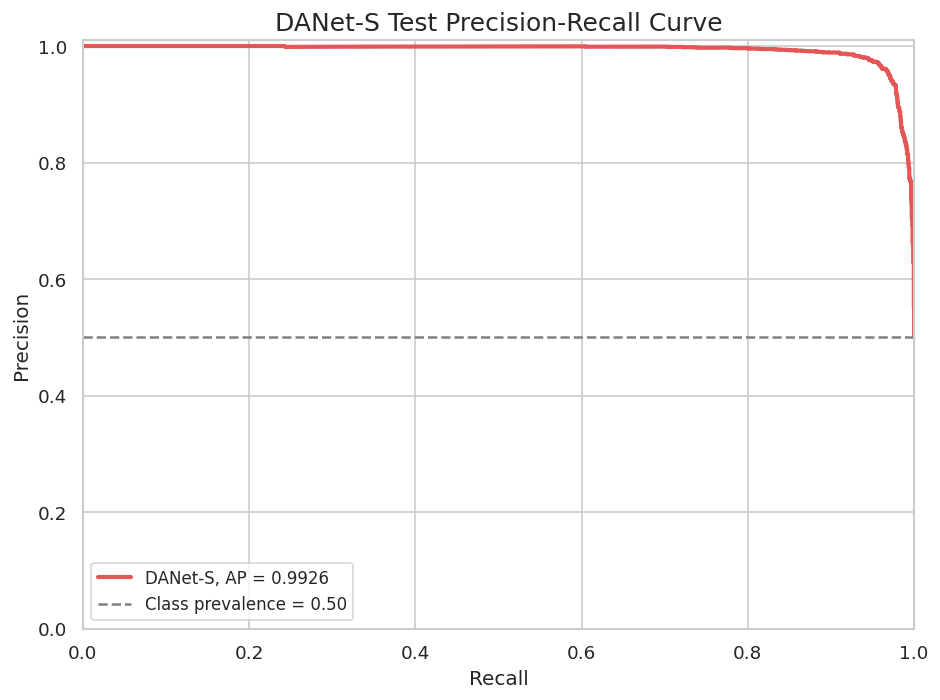

Average precision: 0.992615
Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/test_precision_recall_curve.png


In [32]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
)

curve_precision, curve_recall, _ = precision_recall_curve(
    true_labels,
    positive_probabilities,
)
average_precision = average_precision_score(
    true_labels,
    positive_probabilities,
)
positive_prevalence = true_labels.mean()

PRECISION_RECALL_PATH = (
    FIGURES_DIR / "test_precision_recall_curve.png"
)

plt.figure(figsize=(8, 6))
plt.plot(
    curve_recall,
    curve_precision,
    color=COLORS["parasitized"],
    linewidth=2.5,
    label=f"DANet-S, AP = {average_precision:.4f}",
)
plt.axhline(
    positive_prevalence,
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label=f"Class prevalence = {positive_prevalence:.2f}",
)
plt.xlim(0, 1)
plt.ylim(0, 1.01)
plt.title("DANet-S Test Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(
    PRECISION_RECALL_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Average precision:", f"{average_precision:.6f}")
print("Figure saved to:", PRECISION_RECALL_PATH)

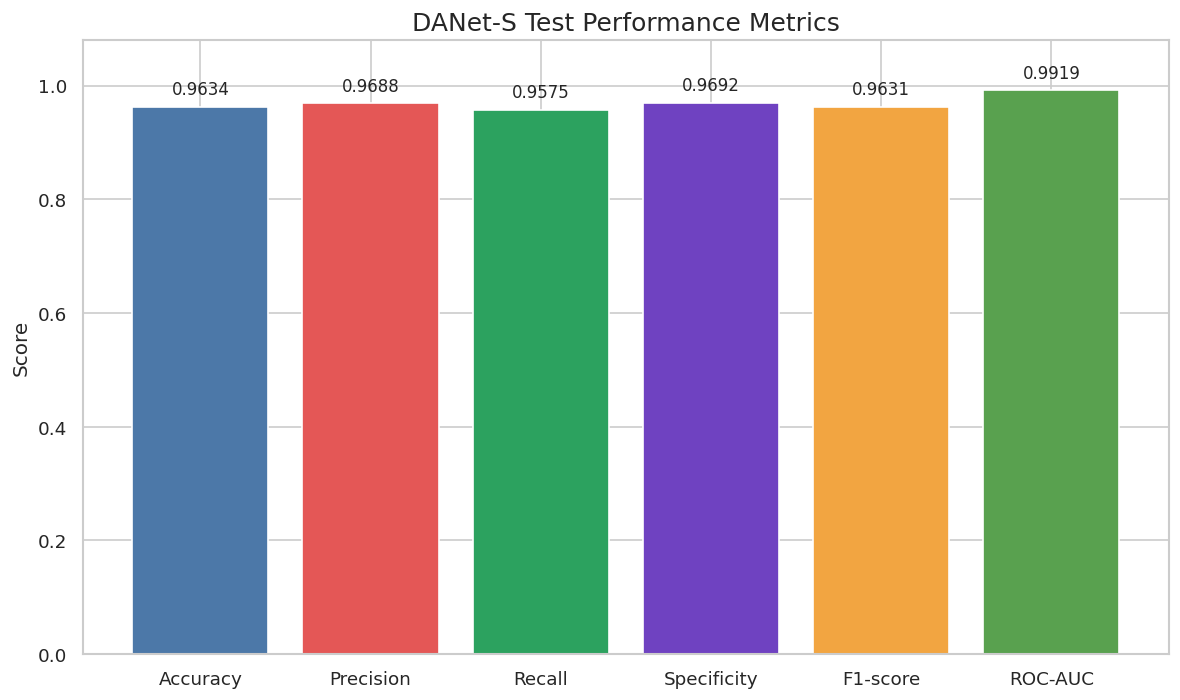

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/test_metric_comparison.png


In [33]:
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "ROC-AUC",
]
metric_values = [
    accuracy,
    precision,
    recall,
    specificity,
    f1,
    roc_auc,
]

METRIC_CHART_PATH = (
    FIGURES_DIR / "test_metric_comparison.png"
)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    metric_names,
    metric_values,
    color=[
        COLORS["uninfected"],
        COLORS["parasitized"],
        COLORS["highlight"],
        COLORS["curve"],
        "#F2A541",
        "#59A14F",
    ],
)

plt.ylim(0, 1.08)
plt.title("DANet-S Test Performance Metrics")
plt.ylabel("Score")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(
    METRIC_CHART_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", METRIC_CHART_PATH)

In [34]:
from sklearn.metrics import classification_report

class_report = classification_report(
    true_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["Uninfected", "Parasitized"],
    output_dict=True,
    zero_division=0,
)

class_report_frame = (
    pd.DataFrame(class_report)
    .transpose()
    .round(6)
)

CLASS_REPORT_PATH = (
    EVALUATION_DIR / "test_classification_report.csv"
)
class_report_frame.to_csv(CLASS_REPORT_PATH)

display(class_report_frame)
print("Classification report saved to:", CLASS_REPORT_PATH)

,precision,recall,f1-score,support
Uninfected,0.958034,0.969158,0.963564,2756.000000
Parasitized,0.968796,0.957547,0.963139,2756.000000
accuracy,0.963353,0.963353,0.963353,0.963353
macro avg,0.963415,0.963353,0.963351,5512.000000
weighted avg,0.963415,0.963353,0.963351,5512.000000


Classification report saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/test_classification_report.csv


## 7. Qualitative prediction analysis

Representative correct predictions, false positives, and false negatives are examined together with the confidence distribution. High confidence errors are included to show the practical limits of the model output.


In [35]:
correct_examples = (
    test_predictions[test_predictions["correct"]]
    .sort_values("confidence", ascending=False)
    .groupby("true_label", group_keys=False)
    .head(2)
    .copy()
)
correct_examples["example_type"] = "Correct"

false_positive_examples = (
    test_predictions[
        (test_predictions["true_label"] == 0)
        & (test_predictions["predicted_label"] == 1)
    ]
    .nlargest(2, "confidence")
    .copy()
)
false_positive_examples["example_type"] = "False positive"

false_negative_examples = (
    test_predictions[
        (test_predictions["true_label"] == 1)
        & (test_predictions["predicted_label"] == 0)
    ]
    .nlargest(2, "confidence")
    .copy()
)
false_negative_examples["example_type"] = "False negative"

example_predictions = pd.concat(
    [
        correct_examples,
        false_positive_examples,
        false_negative_examples,
    ],
    ignore_index=True,
)

EXAMPLE_RECORDS_PATH = (
    EVALUATION_DIR / "prediction_examples.csv"
)
example_predictions.to_csv(
    EXAMPLE_RECORDS_PATH,
    index=False,
)

display(
    example_predictions[
        [
            "example_type",
            "true_class",
            "predicted_class",
            "confidence",
            "relative_path",
        ]
    ]
)

print("Example records saved to:", EXAMPLE_RECORDS_PATH)

,example_type,true_class,predicted_class,confidence,relative_path
0,Correct,Uninfected,Uninfected,0.999975,Uninfected/C222ThinF_IMG_20151115_151015_cell_...
1,Correct,Uninfected,Uninfected,0.999972,Uninfected/C53P14thinF_IMG_20150726_114404_cel...
2,Correct,Parasitized,Parasitized,0.999931,Parasitized/C136P97ThinF_IMG_20151005_141552_c...
3,Correct,Parasitized,Parasitized,0.999929,Parasitized/C33P1thinF_IMG_20150619_115808a_ce...
4,False positive,Uninfected,Parasitized,0.999839,Uninfected/C128P89ThinF_IMG_20151004_131753_ce...
5,False positive,Uninfected,Parasitized,0.999214,Uninfected/C69P30N_ThinF_IMG_20150819_135421_c...
6,False negative,Parasitized,Uninfected,0.999807,Parasitized/C116P77ThinF_IMG_20150930_171954_c...
7,False negative,Parasitized,Uninfected,0.998875,Parasitized/C173P134NThinF_IMG_20151130_120046...


Example records saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/prediction_examples.csv


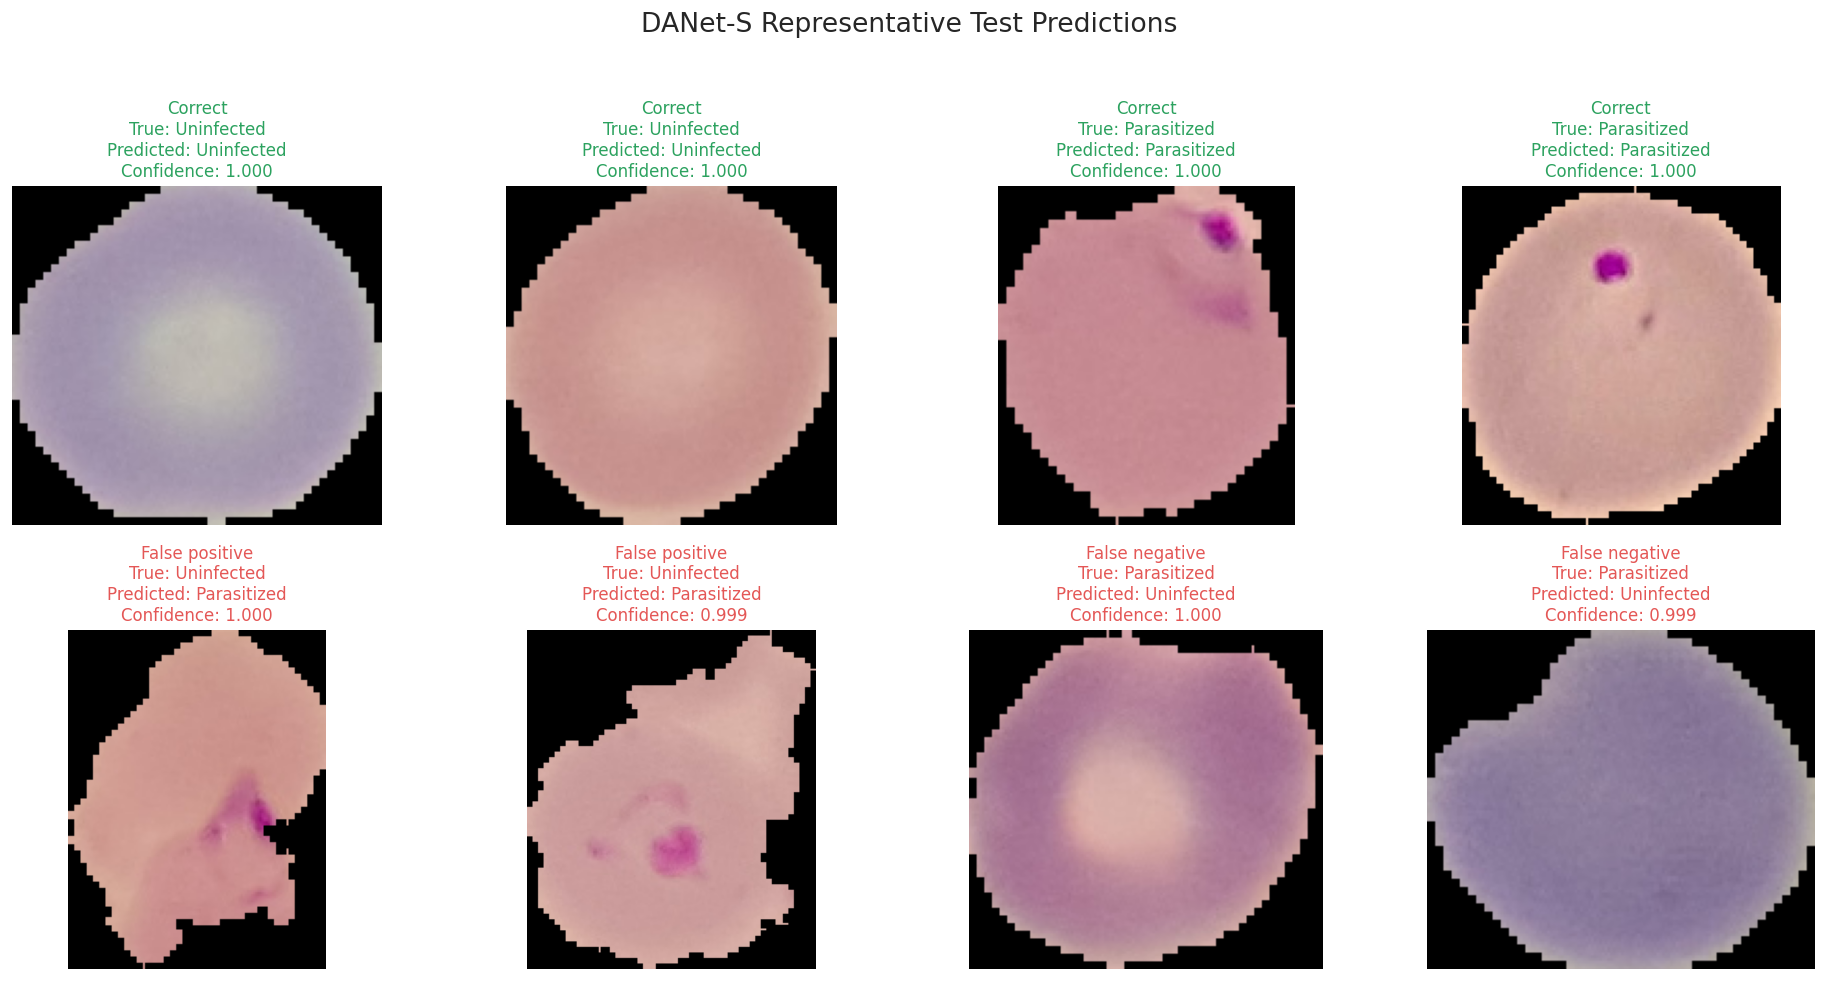

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/prediction_examples.png


In [36]:
PREDICTION_EXAMPLES_PATH = (
    FIGURES_DIR / "prediction_examples.png"
)

figure, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8),
)

for axis, (_, row) in zip(
    axes.ravel(),
    example_predictions.iterrows(),
):
    image_path = IMAGE_DIR / row["relative_path"]

    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))

    title_color = (
        COLORS["highlight"]
        if row["correct"]
        else COLORS["parasitized"]
    )

    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {row['true_class']}\n"
        f"Predicted: {row['predicted_class']}\n"
        f"Confidence: {row['confidence']:.3f}",
        color=title_color,
        fontsize=10,
    )
    axis.axis("off")

figure.suptitle(
    "DANet-S Representative Test Predictions",
    fontsize=16,
    y=1.02,
)
figure.tight_layout()
figure.savefig(
    PREDICTION_EXAMPLES_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", PREDICTION_EXAMPLES_PATH)

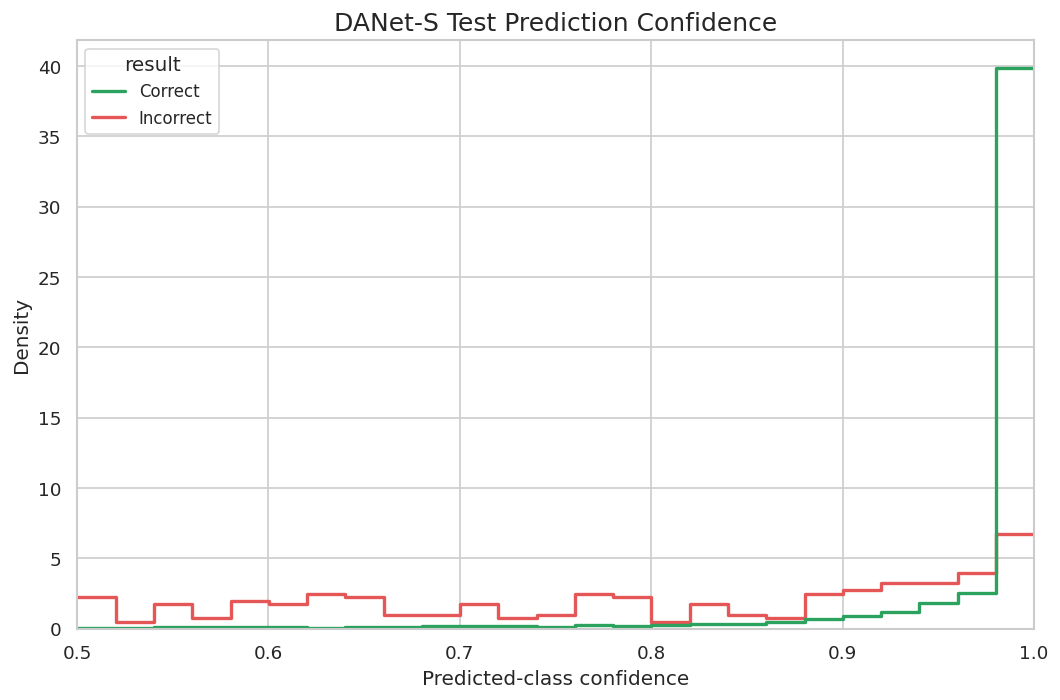

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/prediction_confidence_distribution.png


In [37]:
CONFIDENCE_PATH = (
    FIGURES_DIR / "prediction_confidence_distribution.png"
)

confidence_plot_frame = test_predictions.copy()
confidence_plot_frame["result"] = np.where(
    confidence_plot_frame["correct"],
    "Correct",
    "Incorrect",
)

plt.figure(figsize=(9, 6))
sns.histplot(
    data=confidence_plot_frame,
    x="confidence",
    hue="result",
    hue_order=["Correct", "Incorrect"],
    palette={
        "Correct": COLORS["highlight"],
        "Incorrect": COLORS["parasitized"],
    },
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    linewidth=2,
)
plt.title("DANet-S Test Prediction Confidence")
plt.xlabel("Predicted-class confidence")
plt.ylabel("Density")
plt.xlim(0.5, 1.0)
plt.tight_layout()
plt.savefig(
    CONFIDENCE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", CONFIDENCE_PATH)

In [38]:
evaluation_metrics["average_precision"] = float(
    average_precision
)
evaluation_metrics["incorrect_predictions"] = int(
    (~test_predictions["correct"]).sum()
)

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(evaluation_metrics, file, indent=2)

print("Updated metrics saved to:", METRICS_PATH)
print(
    "Average precision:",
    f"{evaluation_metrics['average_precision']:.6f}",
)
print(
    "Incorrect predictions:",
    evaluation_metrics["incorrect_predictions"],
)

Updated metrics saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/test_metrics.json
Average precision: 0.992615
Incorrect predictions: 202


## 8. Comparison with the base paper

The reproduced test metrics are compared with the published DANet-S with LogSoftMax results. The comparison is descriptive because random split membership and implementation details may differ.

Base paper: [Ali et al., Scientific Reports, 2025](https://doi.org/10.1038/s41598-025-20402-1)


In [39]:
paper_metrics = {
    "Accuracy": 0.9795,
    "Precision": 0.9776,
    "Recall/Sensitivity": 0.9807,
    "Specificity": 0.9787,
    "F1-score": 0.9786,
}

reproduced_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall/Sensitivity": recall,
    "Specificity": specificity,
    "F1-score": f1,
}

comparison_frame = pd.DataFrame(
    {
        "Base paper": paper_metrics,
        "Reproduction": reproduced_metrics,
    }
)

comparison_frame["Difference"] = (
    comparison_frame["Reproduction"]
    - comparison_frame["Base paper"]
)
comparison_frame["Difference in percentage points"] = (
    comparison_frame["Difference"] * 100
)

COMPARISON_PATH = (
    EVALUATION_DIR / "base_paper_comparison.csv"
)
comparison_frame.to_csv(COMPARISON_PATH)

display(comparison_frame.round(6))
print("Comparison saved to:", COMPARISON_PATH)

,Base paper,Reproduction,Difference,Difference in percentage points
Accuracy,0.9795,0.963353,-0.016147,-1.614731
Precision,0.9776,0.968796,-0.008804,-0.880411
Recall/Sensitivity,0.9807,0.957547,-0.023153,-2.315283
Specificity,0.9787,0.969158,-0.009542,-0.954180
F1-score,0.9786,0.963139,-0.015461,-1.546131


Comparison saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/base_paper_comparison.csv


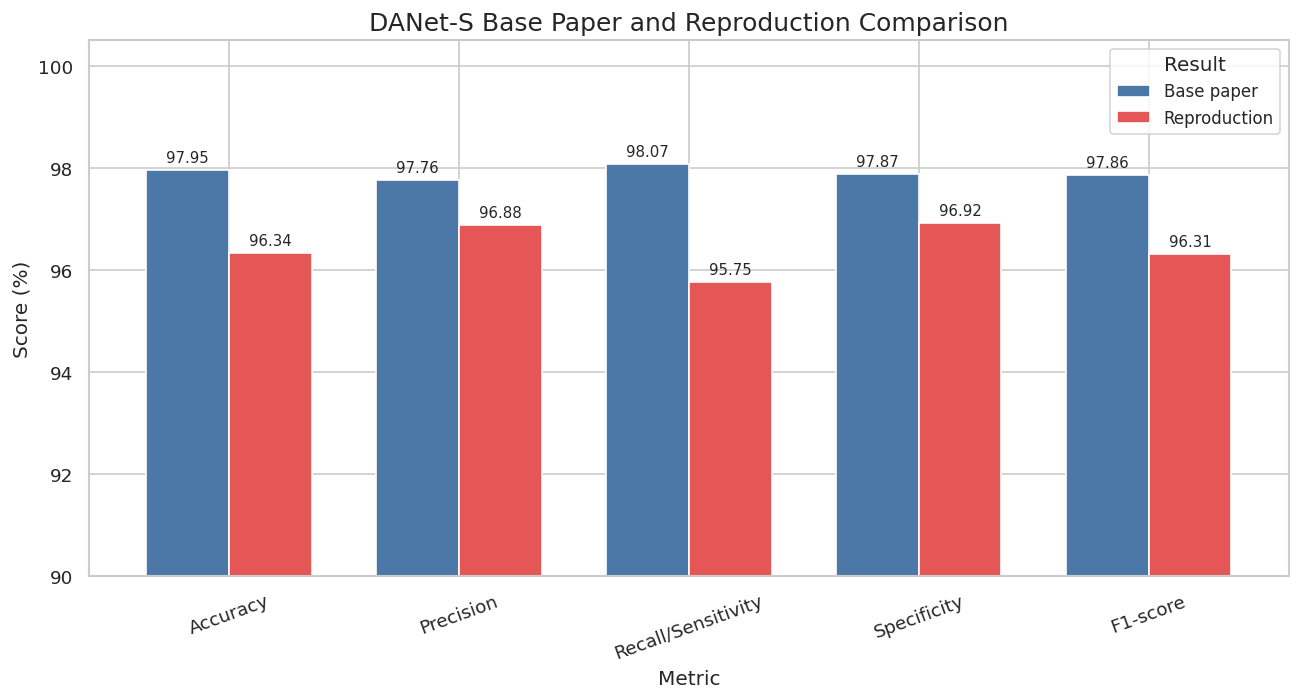

Figure saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/figures/base_paper_comparison.png


In [40]:
comparison_percent = (
    comparison_frame[["Base paper", "Reproduction"]]
    * 100
)

COMPARISON_FIGURE_PATH = (
    FIGURES_DIR / "base_paper_comparison.png"
)

axis = comparison_percent.plot(
    kind="bar",
    figsize=(11, 6),
    color=[
        COLORS["uninfected"],
        COLORS["parasitized"],
    ],
    width=0.72,
)

axis.set_title(
    "DANet-S Base Paper and Reproduction Comparison"
)
axis.set_xlabel("Metric")
axis.set_ylabel("Score (%)")
axis.set_ylim(90, 100.5)
axis.tick_params(axis="x", rotation=20)
axis.legend(title="Result")

for container in axis.containers:
    axis.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9,
    )

plt.tight_layout()
plt.savefig(
    COMPARISON_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figure saved to:", COMPARISON_FIGURE_PATH)

## 9. Summary, limitations, and reproducibility artifacts

The final summary records the main results and explicitly documents the image-level split, patient overlap, confidence limitations, and evaluation boundary. Configuration files, tables, figures, and checksums are saved for review.


In [41]:
summary_text = f"""# DANet-S Final Test Evaluation

## Evaluation setup

- Dataset: NIH/NLM Malaria Cell Images
- Selected model: DANet-S with LogSoftMax
- Selected checkpoint epoch: {checkpoint["epoch"]}
- Test images: {len(test_predictions):,}
- Uninfected test images: {(true_labels == 0).sum():,}
- Parasitized test images: {(true_labels == 1).sum():,}
- Input size: {INPUT_SIZE[0]} x {INPUT_SIZE[1]}
- Trainable parameters: {total_parameters:,}
- Test split usage: Final evaluation only

## Reproduced test results

- Test loss: {test_loss:.6f}
- Accuracy: {accuracy:.6f} ({accuracy * 100:.2f}%)
- Precision: {precision:.6f} ({precision * 100:.2f}%)
- Recall or sensitivity: {recall:.6f} ({recall * 100:.2f}%)
- Specificity: {specificity:.6f} ({specificity * 100:.2f}%)
- F1-score: {f1:.6f} ({f1 * 100:.2f}%)
- ROC-AUC: {roc_auc:.6f}
- Average precision: {average_precision:.6f}

## Confusion matrix

- True negatives: {tn:,}
- False positives: {fp:,}
- False negatives: {fn:,}
- True positives: {tp:,}
- Total incorrect predictions: {fp + fn:,}

## Base-paper comparison

The base paper reports 97.95% accuracy, 97.76% precision,
98.07% sensitivity, 97.87% specificity, and 97.86% F1-score
for DANet-S with LogSoftMax.

The reproduction achieved 96.34% accuracy and 96.31% F1-score.
Its accuracy is {abs((accuracy - paper_metrics["Accuracy"]) * 100):.2f}
percentage points below the paper, and its F1-score is
{abs((f1 - paper_metrics["F1-score"]) * 100):.2f} percentage points
below the paper.

Base paper:
https://doi.org/10.1038/s41598-025-20402-1

## Interpretation

The reproduced model maintains balanced performance across both
classes. Specificity is slightly higher than sensitivity, and the
confusion matrix contains more false negatives than false positives.
The ROC-AUC and average precision indicate strong discrimination on
this fixed test split.

Some incorrect examples have high predicted confidence. Therefore,
the output confidence should not be interpreted as calibrated
clinical certainty.

## Limitations

- The manifest follows the base paper's stratified image-level split.
- Images associated with the same mapped patient identifier occur
  across training, validation, and test splits.
- Patient overlap can make image-level results more optimistic than
  results from a patient-independent evaluation.
- The comparison uses one fixed split and does not reproduce the
  paper's complete cross-validation analysis.
- Differences from the paper may result from random split membership,
  implementation details, numerical precision, and the recovered
  training schedule.
- These experimental results do not establish clinical validity and
  must not be used for diagnosis.

## Evaluation boundary

The test split was not used for training or checkpoint selection.
The Epoch {checkpoint["epoch"]} checkpoint was selected using
validation loss before this final test evaluation.
"""

SUMMARY_PATH = EVALUATION_DIR / "danet_evaluation_summary.md"
SUMMARY_PATH.write_text(summary_text, encoding="utf-8")

print(summary_text)
print("Summary saved to:", SUMMARY_PATH)

# DANet-S Final Test Evaluation

## Evaluation setup

- Dataset: NIH/NLM Malaria Cell Images
- Selected model: DANet-S with LogSoftMax
- Selected checkpoint epoch: 67
- Test images: 5,512
- Uninfected test images: 2,756
- Parasitized test images: 2,756
- Input size: 224 x 224
- Trainable parameters: 2,310,842
- Test split usage: Final evaluation only

## Reproduced test results

- Test loss: 0.110878
- Accuracy: 0.963353 (96.34%)
- Precision: 0.968796 (96.88%)
- Recall or sensitivity: 0.957547 (95.75%)
- Specificity: 0.969158 (96.92%)
- F1-score: 0.963139 (96.31%)
- ROC-AUC: 0.991887
- Average precision: 0.992615

## Confusion matrix

- True negatives: 2,671
- False positives: 85
- False negatives: 117
- True positives: 2,639
- Total incorrect predictions: 202

## Base-paper comparison

The base paper reports 97.95% accuracy, 97.76% precision,
98.07% sensitivity, 97.87% specificity, and 97.86% F1-score
for DANet-S with LogSoftMax.

The reproduction achieved 96.34% accuracy and 96.31% F

In [42]:
import hashlib


def calculate_sha256(file_path):
    digest = hashlib.sha256()

    with open(file_path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()


artifact_paths = [
    PREDICTIONS_PATH,
    METRICS_PATH,
    CLASS_REPORT_PATH,
    EXAMPLE_RECORDS_PATH,
    COMPARISON_PATH,
    SUMMARY_PATH,
    CONFUSION_MATRIX_PATH,
    ROC_CURVE_PATH,
    PRECISION_RECALL_PATH,
    METRIC_CHART_PATH,
    PREDICTION_EXAMPLES_PATH,
    CONFIDENCE_PATH,
    COMPARISON_FIGURE_PATH,
]

artifact_records = []

for artifact_path in artifact_paths:
    artifact_records.append(
        {
            "file": str(
                artifact_path.relative_to(EVALUATION_DIR)
            ),
            "size_mb": round(
                artifact_path.stat().st_size / (1024**2),
                3,
            ),
            "sha256": calculate_sha256(artifact_path),
        }
    )

ARTIFACT_MANIFEST_PATH = (
    EVALUATION_DIR / "evaluation_artifact_manifest.json"
)

with open(
    ARTIFACT_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(artifact_records, file, indent=2)

artifact_frame = pd.DataFrame(artifact_records)

display(artifact_frame)
print(
    "Artifact manifest saved to:",
    ARTIFACT_MANIFEST_PATH,
)
print("Artifacts recorded:", len(artifact_records))

,file,size_mb,sha256
0,test_predictions.csv,0.780,6549e7538c78bfb2537dad295eb01dfa9e965cea48e547...
1,test_metrics.json,0.001,96071cc7cdd3458ecfa1a6f4e0769b9d2a249a9b47eef7...
2,test_classification_report.csv,0.000,3260a9c11a2e996d3a93098ec4e4a2f1a5a0d369b4fad8...
3,prediction_examples.csv,0.001,f2705a25f3b8ab7fd4441d0862bf63c415deea2cfd3d4d...
4,base_paper_comparison.csv,0.000,d06cee4b9f990e62a5e1095a64b29e0bdaa3714a506e9f...
5,danet_evaluation_summary.md,0.002,3c35a8ba9bf092fbbec2ce9b98cdf7011863275578fa27...
6,figures/test_confusion_matrix.png,0.102,95402e85eaaf4b7fd494d55c66ff03f12143e5249ee6de...
7,figures/test_roc_curve.png,0.141,63eec6590dfdd413dca744f88d7bf80634dd6a0536406b...
8,figures/test_precision_recall_curve.png,0.103,9df77d8d878baebc6ba994a4b7d8892a01225ae3c92a3f...
9,figures/test_metric_comparison.png,0.107,aa759c5bcbca4f0d60c0c4ac3c05adf30ac8f1d9e4a068...


Artifact manifest saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/evaluation_artifact_manifest.json
Artifacts recorded: 13


In [43]:
import torchvision

evaluation_config = {
    "model": "DANet-S with LogSoftMax",
    "checkpoint_file": CHECKPOINT_PATH.name,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_sha256": calculate_sha256(
        CHECKPOINT_PATH
    ),
    "input_size": list(INPUT_SIZE),
    "batch_size": BATCH_SIZE,
    "data_loader_workers": test_loader.num_workers,
    "test_samples": len(test_dataset),
    "test_transform": [
        f"Resize({INPUT_SIZE})",
        "ToTensor()",
    ],
    "loss": "NLLLoss with sum reduction",
    "device": str(DEVICE),
    "random_seed": SEED,
    "class_mapping": data_config["class_mapping"],
    "split_protocol": data_config["split_protocol"],
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "base_paper_doi": data_config["base_paper_doi"],
}

EVALUATION_CONFIG_PATH = (
    EVALUATION_DIR / "evaluation_config.json"
)

with open(
    EVALUATION_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(evaluation_config, file, indent=2)

print(
    "Evaluation configuration saved to:",
    EVALUATION_CONFIG_PATH,
)
print(
    "Checkpoint SHA-256:",
    evaluation_config["checkpoint_sha256"],
)

Evaluation configuration saved to: /content/drive/MyDrive/malaria_danet/danet_evaluation/evaluation_config.json
Checkpoint SHA-256: d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1


In [44]:
artifact_paths.append(EVALUATION_CONFIG_PATH)

artifact_records = [
    {
        "file": str(path.relative_to(EVALUATION_DIR)),
        "size_mb": round(
            path.stat().st_size / (1024**2),
            3,
        ),
        "sha256": calculate_sha256(path),
    }
    for path in artifact_paths
]

with open(
    ARTIFACT_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(artifact_records, file, indent=2)

print(
    "Artifact manifest updated:",
    ARTIFACT_MANIFEST_PATH,
)
print("Final artifact count:", len(artifact_records))

Artifact manifest updated: /content/drive/MyDrive/malaria_danet/danet_evaluation/evaluation_artifact_manifest.json
Final artifact count: 14


In [45]:
with open(
    ARTIFACT_MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as file:
    saved_artifacts = json.load(file)

missing_artifacts = []
hash_mismatches = []

for record in saved_artifacts:
    artifact_path = EVALUATION_DIR / record["file"]

    if not artifact_path.exists():
        missing_artifacts.append(record["file"])
        continue

    if calculate_sha256(artifact_path) != record["sha256"]:
        hash_mismatches.append(record["file"])

saved_predictions = pd.read_csv(PREDICTIONS_PATH)

print("Artifacts recorded:", len(saved_artifacts))
print("Missing artifacts:", missing_artifacts)
print("Hash mismatches:", hash_mismatches)
print("Prediction rows:", len(saved_predictions))
print(
    "Incorrect predictions:",
    int((~saved_predictions["correct"]).sum()),
)
print(
    "Final accuracy:",
    f"{saved_predictions['correct'].mean():.6f}",
)

assert len(saved_artifacts) == 14
assert not missing_artifacts
assert not hash_mismatches
assert len(saved_predictions) == 5512
assert int((~saved_predictions["correct"]).sum()) == 202

print("Final evaluation artifact verification passed.")

Artifacts recorded: 14
Missing artifacts: []
Hash mismatches: []
Prediction rows: 5512
Incorrect predictions: 202
Final accuracy: 0.963353
Final evaluation artifact verification passed.
